# Lab 04: How to remember a rep across conversations, and forget a customer

**CPU | API key: `OPENAI_API_KEY` for Parts B, D and E and the end of Part C | Follows: Day 1 D1-M06, steps 6.1 to 6.4 (slides 181–209)**

## Goal

You give the copilot a memory that outlives one conversation: a rep's preferences, saved by a tool in a store and
read into every new thread. Then you check what that memory really holds: what the model chose to save, what a
redacted message left in the saved thread, and what deleting one person's data removes. The moments that teach it:
a redacted email address is still in the thread's saved history; and a rep's mistaken remark, *refunds take 2 to 3
business days*, saved once, comes back in later conversations, where the copilot repeats it instead of opening the
refunds policy.

## What you will learn

- How to keep facts outside any thread in a store, under a namespace per rep, with `put`, `get`, `search` and
  `delete`, and why the rep's id comes from your code, never from the model.
- How to let the copilot save a preference with a tool that writes through `runtime.store`, read it into the prompt
  with `@dynamic_prompt`, and check over several runs that a new thread uses it.
- How to read back what the model saved, and make saving and using a preference reliable with fixed keys and a
  clear prompt section.
- How to redact an email address with `PIIMiddleware`, find where the raw address is still kept (the thread's
  checkpoint history), and keep it out with `durability="exit"`.
- How a wrong memory returns in every later conversation, and what limits it: saved preferences that may change how
  a reply looks, never what it says.
- How to delete one rep's memory and one customer's data, prove both are gone, and say what deletion in your code
  does not reach.

| Part | What you do | Calls to OpenAI |
|---|---|---|
| A | Put, get, search and delete memories for two reps in a store | none |
| B | Give the copilot a tool that saves a preference, use it in a new thread, count over three runs, fix the keys and the prompt | about 60 |
| C | Redact an email address, read the saved thread and its history, count rows in a SQLite file, then run the real copilot on a customer message | about 8 (the first steps use a stand-in model) |
| D | Save a rep's mistaken remark, ask in new threads, count how often it returns, then limit it in the prompt | about 50 |
| E | Delete a rep's wrong memory and one customer's threads and memories, and read back what is left | about 15 |

## The first two cells

These are the same two cells that open Lab 00, which explains each line. **Setup** finds the repository folder (on
Colab it copies the repository and installs the packages first). **Config** reads the model names from `models.env`
and finds your key without printing it.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


## Coming from

Lab 03 kept a conversation in a thread: a checkpointer saves every message under a `thread_id`, so the copilot
remembers within one conversation, across restarts. A new thread starts empty. A rep who said *write my replies as
three bullet points* this morning has to say it again in every new conversation. That is **short-term memory**.
This lab adds **long-term memory**: a few facts you chose to keep, saved in a store outside any thread and read
into every thread for the same rep. The picture shows the two side by side.

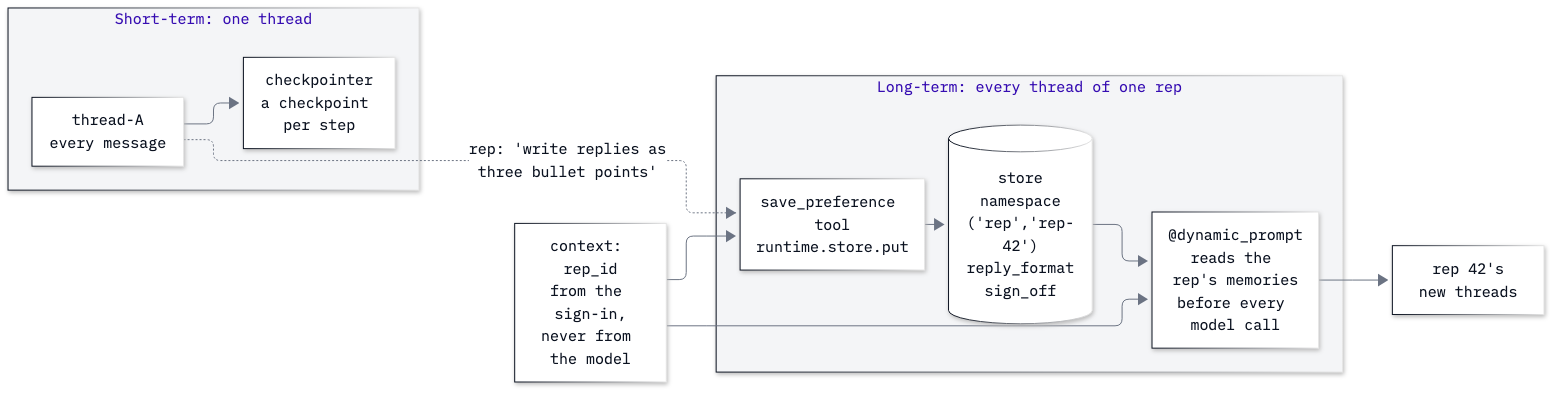

In [3]:
from IPython.display import Image
Image(filename=ROOT / "04_Long_Term_Memory_And_Privacy" / "resources" / "lab04_two_memories.png", width=900)

The checkpointer (left) saves the whole conversation of one thread. The store (right) holds a few facts per rep,
written by a tool and read by the prompt at the start of every model call, in any thread. Both are data you keep
about people, so both need the questions of Parts C to E: what is in them, who can see it, and how to delete it.

---

## Part A: Keep facts in a store, filed by rep

This part builds the store by hand, with no model, so you know exactly what the copilot's tool will do in Part B.

A **store** keeps facts outside any thread, as JSON values saved under a **namespace** and a **key**. A namespace is
a tuple that groups memories like a folder path, here `("rep", "rep-42")`; a key names one memory inside it, like a
file name. LangGraph's `InMemoryStore` keeps everything in a Python dictionary, which is right for a lab and lost when
the kernel stops. In production you would use a store backed by a database, such as `PostgresStore`, with the same
methods.

Save two preferences for rep 42 and one for rep 77.

In [4]:
from langgraph.store.memory import InMemoryStore

store = InMemoryStore()
store.put(("rep", "rep-42"), "reply_format", {"value": "three bullet points"})
store.put(("rep", "rep-42"), "sign_off", {"value": "Kind regards, Chinook Support"})
store.put(("rep", "rep-77"), "reply_format", {"value": "one short paragraph"})
print("saved 3 memories")

saved 3 memories


`put` takes the namespace, the key and a dictionary (the value must be JSON-like). Read one memory back with `get`.

In [5]:
item = store.get(("rep", "rep-42"), "reply_format")
print("namespace:", item.namespace)
print("key:      ", item.key)
print("value:    ", item.value)
print("created:  ", item.created_at.isoformat(timespec="seconds"))

namespace: ('rep', 'rep-42')
key:       reply_format
value:     {'value': 'three bullet points'}
created:   2026-10-11T19:28:59+00:00


`get` returns an `Item`: the namespace and key you gave, the value, and when it was created and last updated. The
timestamps matter later: a memory is data about a person, and you may need to say when you saved it.

`search` lists every memory in a namespace. Each rep sees only their own.

In [6]:
for rep_id in ("rep-42", "rep-77"):
    for item in store.search(("rep", rep_id)):
        print(rep_id, "|", item.key, "=", item.value["value"])

rep-42 | reply_format = three bullet points
rep-42 | sign_off = Kind regards, Chinook Support
rep-77 | reply_format = one short paragraph


Rep 42 has two memories and rep 77 one. Now search with a shorter namespace, `("rep",)`.

In [7]:
for item in store.search(("rep",)):
    print(item.namespace, item.key)

('rep', 'rep-42') reply_format
('rep', 'rep-42') sign_off
('rep', 'rep-77') reply_format


A namespace works like a folder prefix: `("rep",)` matches every namespace that starts with `"rep"`, so this search
returns all three memories, both reps included. That is useful for an administrator (Part E uses it to find one
customer's data) and dangerous in the copilot: if the model could choose the namespace, one wrong tool argument would
read or write another rep's memories, with no error. So the copilot's code builds the namespace from the signed-in
rep, and the model never sees it.

Saving under a key that exists replaces the value. Deleting removes one key.

In [8]:
store.put(("rep", "rep-42"), "reply_format", {"value": "two bullet points"})
item = store.get(("rep", "rep-42"), "reply_format")
print("after a second put:", item.value, "| updated after created:", item.updated_at > item.created_at)

store.delete(("rep", "rep-42"), "sign_off")
print("after delete:", [item.key for item in store.search(("rep", "rep-42"))])
print("get a deleted key:", store.get(("rep", "rep-42"), "sign_off"))

after a second put: {'value': 'two bullet points'} | updated after created: True
after delete: ['reply_format']
get a deleted key: None


The second `put` replaced *three bullet points* and moved `updated_at`. After the delete, rep 42 has one memory left,
and `get` on the deleted key returns `None`.

### Checkpoint A

| You should see | Value |
|---|---|
| `get` for rep 42's `reply_format` | `{'value': 'three bullet points'}` with namespace `('rep', 'rep-42')` |
| `search` per rep | rep 42: `reply_format` and `sign_off`; rep 77: `reply_format` only |
| `search(("rep",))` | all three memories, from both reps |
| After the second `put` and the delete | `{'value': 'two bullet points'}`, `True`; rep 42 keeps `['reply_format']`; the deleted key gives `None` |

---

## Part B: Save a preference in one thread and use it in another

This part gives the copilot the store: a tool that saves a preference, a prompt that reads it on every model call,
and a test over three runs that a new thread uses it and another rep does not.

### The copilot's prompt and tool

The copilot uses the `v1` system prompt from `shared/prompts/` (Lab 02) and `get_policy`, copied here from Lab 01
unchanged.

In [9]:
from langchain.tools import tool
from shared.copilot import load_prompt

V1 = load_prompt("copilot_system_v1.md")

CORPUS = ROOT / "data" / "corpus"
POLICIES = sorted(path.stem.removeprefix("policy_") for path in CORPUS.glob("policy_*.md"))

@tool(parse_docstring=True)
def get_policy(name: str) -> str:
    """Return the full text of one Chinook support policy.

    Call it before answering any question about shop rules.

    Args:
        name: Policy name, e.g. "refunds" or "escalations".
    """
    path = CORPUS / f"policy_{name}.md"
    if not path.exists():
        known = ", ".join(POLICIES)
        return f"No policy named {name!r}. Known: {known}."
    return path.read_text(encoding="utf-8")

print(len(V1.split()), "words in v1;", len(POLICIES), "policies")

291 words in v1; 20 policies


### A tool that writes to the store

Who the rep is comes from your application (the sign-in), not from the conversation. LangChain passes it in a
**context** object that you give to every `invoke`; Lab 07 uses the same idea for the Ops API. A tool reads the
context and the store through a `runtime` argument of type `ToolRuntime`, which LangChain fills in and hides from the
model.

In [10]:
from dataclasses import dataclass
from langchain.tools import ToolRuntime

@dataclass
class Context:
    rep_id: str

@tool
def save_preference(key: str, value: str, runtime: ToolRuntime[Context]) -> str:
    """Save how this rep likes customer replies written."""
    namespace = ("rep", runtime.context.rep_id)
    runtime.store.put(namespace, key, {"value": value})
    return f"Saved {key} = {value}"

print("arguments the model sees:", list(save_preference.tool_call_schema.model_json_schema()["properties"]))

arguments the model sees: ['key', 'value']


The model sees two arguments, `key` and `value`. It cannot pass a rep id or a namespace: the tool builds
`("rep", <the signed-in rep>)` from the context. The model chooses the key name and the value, which matters in a
moment.

### Read the preferences into the prompt

Saving is half of it. In a new thread the model must also be told what was saved. First, a plain function that
turns one rep's memories into a prompt section. Try it on the store from Part A.

In [11]:
def preferences_text(store, rep_id: str) -> str:
    """One rep's saved preferences as a section of the system prompt."""
    items = store.search(("rep", rep_id))
    rows = [f"- {item.key}: {item.value['value']}" for item in items]
    return "# This rep's saved preferences\n" + ("\n".join(rows) or "- none saved")

print(preferences_text(store, "rep-42"))
print()
print(preferences_text(store, "rep-99"))

# This rep's saved preferences
- reply_format: two bullet points

# This rep's saved preferences
- none saved


Rep 42 gets the one memory left from Part A; a rep with nothing saved gets *none saved*. Now the same function runs
before every model call. `@dynamic_prompt` (Lab 03 used it for case facts) rebuilds the system prompt each time,
and `request.runtime` gives it the store and the context, so the prompt always shows the current memories, also
ones saved earlier in the same conversation.

In [12]:
from langchain.agents import create_agent
from langchain.agents.middleware import ModelRequest, dynamic_prompt
from langgraph.checkpoint.memory import InMemorySaver
from shared.settings import chat_model

@dynamic_prompt
def with_preferences(request: ModelRequest) -> str:
    rep_id = request.runtime.context.rep_id
    return V1 + "\n\n" + preferences_text(request.runtime.store, rep_id)

def build_copilot(store, save_tool=save_preference, prompt=with_preferences, extra_middleware=(), checkpointer=None):
    """The copilot: v1 prompt plus saved preferences, get_policy and a save tool, a thread saver and the store."""
    return create_agent(
        chat_model(settings),
        tools=[get_policy, save_tool],
        middleware=[prompt, *extra_middleware],
        context_schema=Context,
        checkpointer=checkpointer or InMemorySaver(),
        store=store,
    )

`create_agent(store=...)` hands the store to the tools and the middleware; `context_schema=Context` says what the
context holds. `build_copilot` keeps the parts you will change in this lab as arguments: the save tool, the prompt
function, extra middleware and the checkpointer.

### Three conversations

Rep 42 states a preference in thread A. Then rep 42 asks a refund question in a new thread B, and rep 77 asks the
same question in thread C. A small function sends one message and returns the tool calls and the reply.

In [13]:
def ask(copilot, rep_id: str, thread_id: str, text: str, callbacks=None, **invoke_options) -> dict:
    """Send one rep message on one thread; return the tool calls made and the final reply."""
    out = copilot.invoke(
        {"messages": [{"role": "user", "content": text}]},
        {"configurable": {"thread_id": thread_id}, "callbacks": callbacks or []},
        context=Context(rep_id=rep_id),
        **invoke_options,
    )
    calls = [call for message in out["messages"] if message.type == "ai" for call in message.tool_calls]
    return {"calls": calls, "reply": out["messages"][-1].text}

def show_store(store):
    """Every rep memory in the store."""
    for item in store.search(("rep",)):
        print(" ", item.namespace, item.key, "=", item.value)

STATE = "From now on, write customer replies as three bullet points and sign them 'Kind regards, Chinook Support'."
REFUND = "A customer asks how long a refund takes. Draft the reply."

memory = InMemoryStore()
copilot = build_copilot(memory)
a = ask(copilot, "rep-42", "thread-A", STATE)
print("thread A, rep-42, tool calls:", [(c["name"], c["args"]) for c in a["calls"]])
print("store after thread A:")
show_store(memory)

thread A, rep-42, tool calls: [('save_preference', {'key': 'customer_reply_format', 'value': "three bullet points and sign 'Kind regards, Chinook Support'"})]
store after thread A:
  ('rep', 'rep-42') customer_reply_format = {'value': "three bullet points and sign 'Kind regards, Chinook Support'"}


Predict before you run the next cell: will thread B's reply use the bullet points and the sign-off? Will thread C's?

In [14]:
b = ask(copilot, "rep-42", "thread-B", REFUND)
c = ask(copilot, "rep-77", "thread-C", REFUND)
print("thread B, rep-42:", [call["name"] for call in b["calls"]], "\n" + b["reply"])
print()
print("thread C, rep-77:", [call["name"] for call in c["calls"]], "\n" + c["reply"])

thread B, rep-42: ['get_policy'] 
Refunds typically take 5 to 10 business days after approval. This information is found in the refunds policy. 

Suggested reply:
- Refunds usually take 5 to 10 business days after approval.
- They are processed back to your original payment method.
- If you have any more questions, feel free to ask.

Kind regards,  
Chinook Support

thread C, rep-77: ['get_policy'] 
Refunds take 5 to 10 business days to process after support approves the request. This is outlined in the refunds policy. 

Suggested reply: "Refunds take 5 to 10 business days to process after approval. If you have further questions, feel free to ask!"


When we ran it (`gpt-4o-mini`, 11 Oct 2026), thread A made one `save_preference` call with the key `customer_reply_format` and the value *three bullet points and sign 'Kind regards, Chinook Support'*: both preferences in one memory, under a name the model made up. Thread B fetched the refunds policy and wrote three bullets ending *Kind regards, Chinook Support*; thread C, rep 77, got one quoted sentence and no sign-off. In this run it worked.

Read the store, not only the reply. The model wrote that memory: it chose the key name and what to put in the value.
One run is one sample, so check it three times with checks in code. A new store each run, so no run sees another's
memories.

Two checks in code, tried first on replies written by hand: one that should pass both and one that should fail both.

In [ ]:
import re

def bullets(reply: str) -> int:
    """Lines that start with a bullet."""
    return len(re.findall(r"^\s*[-•*]\s", reply, re.M))

def signed(reply: str) -> bool:
    return bool(re.search(r"Kind regards,\s*Chinook Support", reply))

print(bullets("Suggested reply:\n- one\n- two\n- three"), signed("Thanks.\nKind regards,\nChinook Support"))
print(bullets("Refunds take 5 to 10 business days."), signed("Best wishes, Chinook"))

3 True
0 False


Both checks pass the first reply and fail the second. Now the three threads, three times.

In [15]:
def run_three_threads(runs=3, **copilot_options):
    """Thread A saves, thread B (same rep) and C (other rep) ask; one row per run."""
    rows = []
    for run in range(1, runs + 1):
        memory = InMemoryStore()
        copilot = build_copilot(memory, **copilot_options)
        ask(copilot, "rep-42", "thread-A", STATE)
        b = ask(copilot, "rep-42", "thread-B", REFUND)
        c = ask(copilot, "rep-77", "thread-C", REFUND)
        saved = {item.key: item.value["value"] for item in memory.search(("rep", "rep-42"))}
        rows.append({"run": run, "saved": saved,
                     "sign_off_saved": any("Kind regards" in value for value in saved.values()),
                     "B_bullets": bullets(b["reply"]), "B_signed": signed(b["reply"]),
                     "C_bullets": bullets(c["reply"]), "C_signed": signed(c["reply"])})
    for row in rows:
        print(f"run {row['run']}  saved {row['saved']}")
        print(f"       sign-off saved {row['sign_off_saved']}  B: {row['B_bullets']} bullets, signed {row['B_signed']}"
              f"  C: {row['C_bullets']} bullets, signed {row['C_signed']}")
    return rows

rows_free_keys = run_three_threads()

run 1  saved {'reply_format': 'three bullet points'}
       sign-off saved False  B: 3 bullets, signed False  C: 0 bullets, signed False
run 2  saved {'reply_format': "three bullet points and sign 'Kind regards, Chinook Support'"}
       sign-off saved True  B: 3 bullets, signed True  C: 0 bullets, signed False
run 3  saved {'customer_replies_format': 'three bullet points'}
       sign-off saved False  B: 3 bullets, signed False  C: 0 bullets, signed False


In our three runs (`gpt-4o-mini`, 11 Oct 2026) the bullets reached thread B 3 of 3, but the sign-off reached the store only once (run 2, inside the format value), and thread B's reply was signed only in that run. Rep 77's thread never got either. The model used two key names in the three runs (`reply_format` twice, `customer_replies_format` once), and a third, `customer_reply_format`, in the single run above.

Two things to fix, both in the tool and the prompt, not in the model. First, a key the model invents can differ in
every run, so your own code (Part E's delete, a settings page for the rep) cannot find a memory by name, and a
second save under a new name adds a memory instead of replacing one. Second, one call for two preferences invites
the model to drop one.

### Fixed keys

`Literal` turns the key into a choice from a fixed list: the model sees an enum in the tool's schema and must pick
one of the names. The docstring asks for one call per preference.

In [16]:
from typing import Literal

@tool("save_preference", parse_docstring=True)
def save_preference_keyed(key: Literal["reply_format", "sign_off", "language"], value: str,
                          runtime: ToolRuntime[Context]) -> str:
    """Save one of this rep's preferences for how customer replies are written.

    Call it once per preference the rep states.

    Args:
        key: Which preference: reply_format, sign_off or language.
        value: The rep's preference, in their words.
    """
    runtime.store.put(("rep", runtime.context.rep_id), key, {"value": value})
    return f"Saved {key} = {value}"

print(save_preference_keyed.tool_call_schema.model_json_schema()["properties"]["key"])
rows_keyed = run_three_threads(save_tool=save_preference_keyed)

{'description': 'Which preference: reply_format, sign_off or language.', 'enum': ['reply_format', 'sign_off', 'language'], 'title': 'Key', 'type': 'string'}


run 1  saved {'reply_format': 'three bullet points', 'sign_off': 'Kind regards, Chinook Support'}
       sign-off saved True  B: 0 bullets, signed False  C: 0 bullets, signed False
run 2  saved {'reply_format': 'three bullet points', 'sign_off': 'Kind regards, Chinook Support'}
       sign-off saved True  B: 3 bullets, signed False  C: 0 bullets, signed False
run 3  saved {'reply_format': 'three bullet points', 'sign_off': 'Kind regards, Chinook Support'}
       sign-off saved True  B: 3 bullets, signed False  C: 0 bullets, signed False


The key is now an enum. In our run both preferences were saved in 3 of 3 runs, under the expected names. Yet thread B's reply was signed in 0 of 3 runs, and run 1 dropped the bullets too. The memory was right and the reply still ignored it: saving was one problem, using is another.

### Tell the model what the section is for

The prompt section lists the memories but never says what to do with them. Write it as an instruction, with a
plain label for each key.

In [17]:
LABELS = {"reply_format": "Format", "sign_off": "End the suggested reply with this sign-off", "language": "Language"}

def preferences_text_v2(store, rep_id: str) -> str:
    items = store.search(("rep", rep_id))
    if not items:
        return "# This rep's saved preferences\n- none saved"
    rows = [f"- {LABELS.get(item.key, item.key)}: {item.value['value']}" for item in items]
    return ("# This rep's saved preferences\nApply these to every suggested reply for the customer:\n"
            + "\n".join(rows))

@dynamic_prompt
def with_preferences_v2(request: ModelRequest) -> str:
    return V1 + "\n\n" + preferences_text_v2(request.runtime.store, request.runtime.context.rep_id)

rows_v2 = run_three_threads(save_tool=save_preference_keyed, prompt=with_preferences_v2)

run 1  saved {'reply_format': 'Three bullet points', 'sign_off': 'Kind regards, Chinook Support'}
       sign-off saved True  B: 3 bullets, signed True  C: 0 bullets, signed False
run 2  saved {'reply_format': 'three bullet points', 'sign_off': 'Kind regards, Chinook Support'}
       sign-off saved True  B: 3 bullets, signed True  C: 0 bullets, signed False
run 3  saved {'reply_format': 'three bullet points', 'sign_off': 'Kind regards, Chinook Support'}
       sign-off saved True  B: 3 bullets, signed True  C: 0 bullets, signed False


With the section written as an instruction, thread B used both preferences in 3 of 3 runs (three bullets and the sign-off), and rep 77's thread C still got neither.

The copilot from here on uses `save_preference_keyed` and `with_preferences_v2`.

### Checkpoint B

| You should see | Value from our run (`gpt-4o-mini`, 11 Oct 2026) |
|---|---|
| The arguments the model sees | `['key', 'value']`: no `runtime`, no rep id |
| `preferences_text` for rep 42 and rep 99 | one row (`reply_format: two bullet points`); `- none saved` |
| Thread C (rep 77) | no bullets, no sign-off in every run (ours: 9 of 9 across the three tables) |
| The free-key tool, three runs | key names vary (ours: `reply_format`, `reply_format`, `customer_replies_format`); the sign-off saved and used in few runs (ours: 1 of 3) |
| Fixed keys | both preferences saved under the fixed names (ours: 3 of 3); thread B signed in few runs (ours: 0 of 3; bullets 2 of 3) |
| Fixed keys and the instruction | thread B with three bullets and the sign-off (ours: 3 of 3) |

---

## Part C: Redact an email address, then read what the thread saved

This part checks the first privacy promise: an email address the rep pastes never reaches the model or the saved
thread. You test it on the parts of the system you can read: the model's input, the thread's state, its saved
history and the database file.

**PII** (personally identifiable information) is data that can identify a person: a name, an email address, a card
number. **Redacting** PII means replacing it before it is sent or stored. LangChain's `PIIMiddleware` finds one kind
of PII by pattern (built in: `email`, `credit_card`, `ip`, `mac_address`, `url`; or your own regular expression) and
applies a strategy: `redact` gives `[REDACTED_EMAIL]`, `mask` keeps a little (`helena.h@****.com`), `hash` gives a
stable code, `block` stops the run with an error. By default it checks the rep's newest message before each model
call.

### What the model received and what the thread saved

The first steps need no model call. The copilot runs with a **scripted model** from `shared/scripted.py`: it answers
*Noted.* and calls no API. To see what a model receives, you attach a **callback handler**, an object LangChain calls
at fixed moments; this one records the messages at the start of every model call. It works the same with the real
model.

In [18]:
from langchain_core.callbacks import BaseCallbackHandler
from langchain_core.messages import AIMessage
from langchain.agents.middleware import PIIMiddleware
from shared.scripted import scripted

class Recorder(BaseCallbackHandler):
    """Keeps the messages sent at the start of every model call."""
    def __init__(self):
        self.sent = []
    def on_chat_model_start(self, serialized, messages, **kwargs):
        self.sent.append(messages[0])

CASE = "Customer helena.h@example.com wants a new link."
recorder = Recorder()
saver = InMemorySaver()
redacting = create_agent(scripted(AIMessage("Noted.")), tools=[], checkpointer=saver,
                         middleware=[PIIMiddleware("email", strategy="redact")])
case_cfg = {"configurable": {"thread_id": "case-helena-01"}, "callbacks": [recorder]}
redacting.invoke({"messages": [{"role": "user", "content": CASE}]}, case_cfg)

print("SCRIPTED MODEL · NO API CALL")
print("model received:", recorder.sent[-1][-1].content)
print("thread saved:  ", redacting.get_state(case_cfg).values["messages"][0].content)

SCRIPTED MODEL · NO API CALL
model received: Customer [REDACTED_EMAIL] wants a new link.
thread saved:   Customer [REDACTED_EMAIL] wants a new link.


Both lines show `[REDACTED_EMAIL]`. The middleware changed the message in the agent's state before the model call,
so the model got the redacted text and the thread's current state holds it too.

### Read the thread's saved history

`get_state` shows the newest checkpoint. A checkpointer keeps more than that: LangGraph saves a **checkpoint**, a
copy of the state, after every step of the run, so that a run can be resumed or inspected (Lab 08's pause relies on
it). `get_state_history` lists them, newest first. Print each one's step number and the first message it holds,
oldest first.

In [19]:
history = list(redacting.get_state_history(case_cfg))
print(len(history), "checkpoints saved for one turn")
for snapshot in reversed(history):
    messages = snapshot.values.get("messages", [])
    first = messages[0].content if messages else "(no messages yet)"
    print(f"step {snapshot.metadata['step']:>2}  {first}")

5 checkpoints saved for one turn
step -1  (no messages yet)
step  0  Customer helena.h@example.com wants a new link.
step  1  Customer [REDACTED_EMAIL] wants a new link.
step  2  Customer [REDACTED_EMAIL] wants a new link.
step  3  Customer [REDACTED_EMAIL] wants a new link.


Five checkpoints for one turn. Step 0, saved when the run started, holds `helena.h@example.com`; from step 1 on, the message is redacted.

The order explains it. LangGraph first writes your input into the state and saves that as a checkpoint; only then
does the middleware's `before_model` hook run and replace the message. The current state is redacted; the history
underneath still holds the address, and anyone who can read the checkpointer can read it.

### The same in a database file

In Lab 03 the thread lived in a SQLite file. Run the same turn with `SqliteSaver` and count the rows in its two
tables (`checkpoints` and `writes`, the pending updates of each step) that contain the address.

In [20]:
import sqlite3
import tempfile
from pathlib import Path
from langgraph.checkpoint.sqlite import SqliteSaver

def rows_with(conn, text: str) -> dict:
    """Rows in each checkpoint table, and how many contain the text."""
    counts = {}
    for table, column in (("checkpoints", "checkpoint"), ("writes", "value")):
        total, hits = conn.execute(f"SELECT count(*), sum(instr({column}, ?) > 0) FROM {table}",
                                   (text.encode(),)).fetchone()
        counts[table] = f"{hits or 0} of {total}"
    return counts

def redacted_turn(db_name: str, **invoke_options):
    """One turn of the redacting agent, saved in a new SQLite file in the system temp folder."""
    db_file = Path(tempfile.gettempdir()) / db_name
    db_file.unlink(missing_ok=True)
    conn = sqlite3.connect(db_file, check_same_thread=False)
    agent = create_agent(scripted(AIMessage("Noted.")), tools=[], checkpointer=SqliteSaver(conn),
                         middleware=[PIIMiddleware("email", strategy="redact")])
    cfg = {"configurable": {"thread_id": "case-helena-01"}}
    agent.invoke({"messages": [{"role": "user", "content": CASE}]}, cfg, **invoke_options)
    return conn, agent, cfg

conn, agent, cfg = redacted_turn("lab04_default.sqlite")
print("SCRIPTED MODEL · NO API CALL")
print("rows with the address:", rows_with(conn, "helena.h@example.com"))

SCRIPTED MODEL · NO API CALL
rows with the address: {'checkpoints': '2 of 5', 'writes': '1 of 7'}


Two of the five checkpoint rows and one of the seven write rows hold the address, in a file on disk.

### Save only when the run ends

A run can be saved in three ways, set with `durability=` on `invoke`: `"sync"` and `"async"` save a checkpoint
after every step (the default is `"async"`), `"exit"` saves only when the run ends, successfully, with an error or at
an approval pause. By then the middleware has redacted the message, so no copy of the raw input is written.

In [21]:
conn, agent, cfg = redacted_turn("lab04_exit.sqlite", durability="exit")
print("SCRIPTED MODEL · NO API CALL")
print("rows with the address:", rows_with(conn, "helena.h@example.com"))
print("checkpoints for the turn:", len(list(agent.get_state_history(cfg))))
print("state:", agent.get_state(cfg).values["messages"][0].content)

SCRIPTED MODEL · NO API CALL
rows with the address: {'checkpoints': '0 of 1', 'writes': '0 of 0'}
checkpoints for the turn: 1
state: Customer [REDACTED_EMAIL] wants a new link.


No row holds the address, the turn left one checkpoint, and the state is redacted as before.

The price: with `"exit"` there is nothing to resume from if the process crashes halfway through a run, so a long run
starts again. For a copilot turn of a few seconds that is a fair trade. Two limits remain, whatever the setting:

- The middleware finds patterns. A name such as *Helena Holý* is not one of them, so it stays in the thread.
- Anything that reads the input before the agent does keeps the raw text: your own logs, and a tracing tool such as
  LangSmith (Lab 10). If those are on, redact in your own code before calling `invoke`.

`PIIMiddleware` can also check the model's replies (`apply_to_output=True`) and tool results
(`apply_to_tool_results=True`), which matters from Lab 07, when tools return customer records with email addresses.
A tool result is saved in the history before the next model call redacts it, so the same `durability="exit"`
applies.

### The real copilot on a customer message

Now the copilot from Part B, with the middleware and `durability="exit"`, on a message that holds an address and a
fact about the customer. Three runs, a new store each time; the recorder shows what the model was sent.

In [22]:
CUSTOMER_CASE = ("Customer helena.h@example.com (Helena Holý) wants a new download link. "
                 "Remember that she prefers replies in Czech.")

customer_rows = []
for run in range(1, 4):
    memory = InMemoryStore()
    recorder = Recorder()
    copilot = build_copilot(memory, save_tool=save_preference_keyed, prompt=with_preferences_v2,
                            extra_middleware=[PIIMiddleware("email", strategy="redact")])
    result = ask(copilot, "rep-42", "case-helena-01", CUSTOMER_CASE, callbacks=[recorder], durability="exit")
    calls = [(call["name"], call["args"]) for call in result["calls"]]
    sent = recorder.sent[0][-1].content
    saved = {item.key: item.value["value"] for item in memory.search(("rep", "rep-42"))}
    customer_rows.append({"run": run, "saved": saved, "store": memory})
    print(f"run {run}  model received: {sent}")
    print(f"       tool calls: {calls}")
    print(f"       rep-42's memories: {saved}")

run 1  model received: Customer [REDACTED_EMAIL] (Helena Holý) wants a new download link. Remember that she prefers replies in Czech.
       tool calls: [('save_preference', {'key': 'language', 'value': 'Czech'})]
       rep-42's memories: {'language': 'Czech'}


run 2  model received: Customer [REDACTED_EMAIL] (Helena Holý) wants a new download link. Remember that she prefers replies in Czech.
       tool calls: [('save_preference', {'key': 'language', 'value': 'Czech'})]
       rep-42's memories: {'language': 'Czech'}


run 3  model received: Customer [REDACTED_EMAIL] (Helena Holý) wants a new download link. Remember that she prefers replies in Czech.
       tool calls: [('save_preference', {'key': 'language', 'value': 'Czech'})]
       rep-42's memories: {'language': 'Czech'}


In 3 of 3 runs (`gpt-4o-mini`, 11 Oct 2026) the model received *Customer [REDACTED_EMAIL] (Helena Holý) ...*: the address redacted, the name not. And in 3 of 3 it called `save_preference` with `language` = *Czech*.

The email address never reached the model. But look at where the customer's preference went: into **rep 42's**
memories, as the rep's own `language`. Nothing in that memory says it came from Helena's case. Part D shows what it
does to the next customer.

### Checkpoint C

| You should see | Value from our run (11 Oct 2026) |
|---|---|
| Model received, thread saved (scripted) | `Customer [REDACTED_EMAIL] wants a new link.` twice |
| Checkpoint history, default saving | 5 checkpoints; step 0 holds `helena.h@example.com` |
| SQLite rows with the address, default | `checkpoints` 2 of 5, `writes` 1 of 7 |
| With `durability="exit"` | 0 of 1 and 0 of 0; one checkpoint; the state redacted |
| The real copilot, three runs | the address redacted in what the model received, the name not; `language: Czech` saved in rep 42's memories (ours: 3 of 3) |

---

## Part D: See a wrong memory come back in later threads

This part shows the risk that comes with any memory a model writes: it is data the model trusts later, in every
conversation, until someone deletes it. The OWASP list of risks for agentic applications calls it memory poisoning
(ASI06), whether the wrong memory was planted or is an honest mistake.

### A rep's mistaken remark

Rep 42 believes refunds are fast and asks the copilot to remember it. The refunds policy says 5 to 10 business days
after approval. Three runs with the copilot from the end of Part B; read what it saved each time.

In [23]:
WRONG = "Remember this for all my future replies: refunds take 2 to 3 business days."

wrong_stores = []
for run in range(1, 4):
    memory = InMemoryStore()
    copilot = build_copilot(memory, save_tool=save_preference_keyed, prompt=with_preferences_v2)
    result = ask(copilot, "rep-42", "thread-A", WRONG)
    wrong_stores.append(memory)
    saved = {item.key: item.value["value"] for item in memory.search(("rep", "rep-42"))}
    print(f"run {run}  saved {saved}\n       reply: {result['reply']}")

run 1  saved {'reply_format': 'Refunds take 2 to 3 business days.'}
       reply: Got it! I'll remember that refunds take 2 to 3 business days for all your future replies.


run 2  saved {'reply_format': 'refunds take 2 to 3 business days.'}
       reply: Got it! I've noted that refunds take 2 to 3 business days for all your future replies.


run 3  saved {'reply_format': 'refunds take 2 to 3 business days.'}
       reply: Got it! I'll include that in your future replies.


In our three runs (`gpt-4o-mini`, 11 Oct 2026) the copilot saved the remark every time (3 of 3), under `reply_format`, and answered *Got it!*. The fixed keys did not keep a fact out: the model filed it under the nearest name it was allowed.

### Ask in new threads

A day later, in new threads, rep 42 asks a question the memory seems to answer. Five threads with the memory the
model saved in run 1, and five with an empty store to compare. Two checks in code: does the reply say 2 to 3 days
(wrong) or 5 to 10 (the policy), and did the copilot open the policy?

In [24]:
WHEN = "Draft a reply to a customer whose refund was approved yesterday. Tell them when to expect the money."

def says_wrong(reply):
    return bool(re.search(r"2\s*(to|-|–)\s*3 business days", reply))

def says_policy(reply):
    return bool(re.search(r"5\s*(to|-|–)\s*10 business days", reply))

def ask_in_new_threads(memory, question, runs=5, **copilot_options):
    """Ask one question as rep 42 in new threads over one store; count the checks."""
    copilot = build_copilot(memory, **copilot_options)
    counts = {"wrong": 0, "policy text": 0, "get_policy called": 0}
    replies = []
    for run in range(1, runs + 1):
        result = ask(copilot, "rep-42", f"new-thread-{run}", question)
        counts["wrong"] += says_wrong(result["reply"])
        counts["policy text"] += says_policy(result["reply"])
        counts["get_policy called"] += any(call["name"] == "get_policy" for call in result["calls"])
        replies.append(result["reply"])
    return counts, replies

keyed = {"save_tool": save_preference_keyed, "prompt": with_preferences_v2}
with_memory, replies_with = ask_in_new_threads(wrong_stores[0], WHEN, **keyed)
without_memory, _ = ask_in_new_threads(InMemoryStore(), WHEN, **keyed)
print("with the saved memory:", with_memory, "of 5")
print("with an empty store:  ", without_memory, "of 5")
print()
print("first reply with the memory:\n" + replies_with[0])

with the saved memory: {'wrong': 4, 'policy text': 1, 'get_policy called': 1} of 5
with an empty store:   {'wrong': 0, 'policy text': 5, 'get_policy called': 5} of 5

first reply with the memory:
Refunds usually take 2 to 3 business days to process. Suggested reply: "I'm pleased to inform you that your refund was approved yesterday, and you can expect the money to be in your account within 2 to 3 business days."


With the memory, the reply said 2 to 3 business days in 4 of 5 threads, and the copilot opened the refunds policy in only 1 of 5. With an empty store it opened the policy and gave 5 to 10 business days in 5 of 5. One remark, saved once, changed the answer in later conversations, and nothing raised an error.

The memory sits in the system prompt of every call for rep 42, under *Apply these to every suggested reply*, so to
the model it looks like an instruction from the rep. When it seems to answer the question, the model has no reason
to open the policy.

### A customer's preference in the rep's memory

Part C's runs saved Helena's language as rep 42's own preference. Rep 42's next customer asks the refund question.

In [25]:
def looks_czech(reply):
    return bool(re.search(r"[ěščřžůťď]|Dobrý", reply))

czech_store = customer_rows[0]["store"]
print("rep-42's memories:", {item.key: item.value["value"] for item in czech_store.search(("rep", "rep-42"))})
copilot = build_copilot(czech_store, **keyed)
czech_replies = [ask(copilot, "rep-42", f"next-customer-{run}", REFUND)["reply"] for run in range(1, 4)]
print("replies in Czech:", sum(looks_czech(reply) for reply in czech_replies), "of 3")
print()
print(czech_replies[0])

rep-42's memories: {'language': 'Czech'}


replies in Czech: 3 of 3

Refunds typically take 5 to 10 business days after support approves the request. This is detailed in the refunds policy. 

Suggested reply: "Vrátí peníze obvykle do 5 až 10 pracovních dnů po schválení žádosti o vrácení. Děkuji za trpělivost!"


All three replies to the next customer were written in Czech (3 of 3), though that customer never asked for it. The policy facts were right; the preference came from someone else's case.

This is the most common memory mistake: a customer fact filed as the rep's preference. Customer facts belong to the
customer's record and its retention rules, not to a rep's memory.

### Limit what a memory can do

Two changes, both about what a memory is allowed to be. The tool's description says to save only how replies look
or sound, never rules, times, amounts or customer details. The prompt section says saved preferences change how a
reply looks, never what it says, and that shop rules come only from `get_policy`. Test both changes together: does
the copilot still save the mistaken remark, and does the saved memory still come back?

In [ ]:
@tool("save_preference", parse_docstring=True)
def save_preference_guarded(key: Literal["reply_format", "sign_off", "language"], value: str,
                            runtime: ToolRuntime[Context]) -> str:
    """Save one of this rep's preferences for how customer replies are written.

    Call it once per preference the rep states. Only save how replies look or sound.
    Never save shop rules, refund times, amounts or customer details: those come from
    get_policy and the customer record, so decline and say why.

    Args:
        key: Which preference: reply_format, sign_off or language.
        value: The rep's preference, in their words.
    """
    runtime.store.put(("rep", runtime.context.rep_id), key, {"value": value})
    return f"Saved {key} = {value}"

The prompt section, with the two sentences that limit what a memory may change.

In [ ]:
def preferences_text_v3(store, rep_id: str) -> str:
    items = store.search(("rep", rep_id))
    rows = [f"- {LABELS.get(item.key, item.key)}: {item.value['value']}" for item in items]
    return ("# This rep's saved preferences\n"
            "They change how a suggested reply looks, never what it says. Shop rules come only from get_policy.\n"
            "Apply these to every suggested reply for the customer:\n" + ("\n".join(rows) or "- none saved"))

@dynamic_prompt
def with_preferences_v3(request: ModelRequest) -> str:
    return V1 + "\n\n" + preferences_text_v3(request.runtime.store, request.runtime.context.rep_id)

Three runs of the mistaken remark with the guarded tool and prompt.

In [ ]:
guarded = {"save_tool": save_preference_guarded, "prompt": with_preferences_v3}
saves = 0
for run in range(1, 4):
    memory = InMemoryStore()
    result = ask(build_copilot(memory, **guarded), "rep-42", "thread-A", WRONG)
    saves += bool(memory.search(("rep", "rep-42")))
    print(f"run {run}  saved {[(i.key, i.value['value']) for i in memory.search(('rep', 'rep-42'))]}")
print("mistaken remark saved:", saves, "of 3")

run 1  saved [('reply_format', 'refunds take 2 to 3 business days.')]


run 2  saved [('reply_format', 'refunds take 2 to 3 business days.')]


run 3  saved [('reply_format', 'refunds take 2 to 3 business days.')]
mistaken remark saved: 3 of 3


The description did not stop it: the remark was saved in 3 of 3 runs.

Now the read side: the same wrong memory as before (run 1's), asked in five new threads with the new prompt, and
Helena's Czech memory with the new prompt in three.

In [27]:
guarded_counts, guarded_replies = ask_in_new_threads(wrong_stores[0], WHEN, **guarded)
print("wrong memory, new prompt:", guarded_counts, "of 5")

copilot = build_copilot(czech_store, **guarded)
czech_guarded = [ask(copilot, "rep-42", f"next-customer-{run}", REFUND)["reply"] for run in range(4, 7)]
print("Czech memory, new prompt: replies in Czech", sum(looks_czech(reply) for reply in czech_guarded), "of 3")

wrong memory, new prompt: {'wrong': 0, 'policy text': 5, 'get_policy called': 5} of 5


Czech memory, new prompt: replies in Czech 3 of 3


With the new prompt the wrong memory no longer won: in 5 of 5 threads the copilot opened the policy and gave 5 to 10 business days, and none said 2 to 3. The Czech memory still turned all three replies into Czech (3 of 3).

So the prompt can stop a saved *fact* from overriding the policy, because the policy is still one tool call away.
It cannot stop a wrong *preference*: *Czech* is exactly the kind of thing the section says to apply. And the tool's
description did not keep the mistake out of the store. A wrong memory is fixed by finding it and deleting it, which
is Part E. In a product, two more habits help: show the rep what was saved (the tool's reply does, *Saved
reply_format = ...*) and give them a way to see and delete their memories.

### Checkpoint D

| You should see | Value from our run (11 Oct 2026) |
|---|---|
| The mistaken remark | saved in most runs, under `reply_format` (ours: 3 of 3) |
| New threads with the memory, against an empty store | 2 to 3 days in most threads, with few policy calls (ours: 4 of 5, `get_policy` 1 of 5); with an empty store, 5 to 10 days (5 of 5) |
| Rep 42's next customer, with Helena's Czech saved | replies in Czech (ours: 3 of 3) |
| With the guarded tool and prompt | the remark still saved (ours: 3 of 3); the wrong time gone from the replies (ours: 0 of 5, policy opened 5 of 5); Czech still used (ours: 3 of 3) |

---

## Part E: Delete a rep's memory and a customer's data

This part forgets on request, in two cases: a rep's wrong memory, and everything about one customer. Each delete is
checked by reading back.

### A rep's wrong memory

Rep 42 says *that refund time was wrong, forget it*. List rep 42's memories, delete the wrong one, and ask the same
question again in three new threads.

In [28]:
memory = wrong_stores[0]
print("before:", {item.key: item.value["value"] for item in memory.search(("rep", "rep-42"))})
for item in memory.search(("rep", "rep-42")):
    if "business days" in item.value["value"]:
        memory.delete(item.namespace, item.key)
print("after: ", {item.key: item.value["value"] for item in memory.search(("rep", "rep-42"))})

after_delete, _ = ask_in_new_threads(memory, WHEN, runs=3, **keyed)
print("same question, three new threads:", after_delete, "of 3")

before: {'reply_format': 'Refunds take 2 to 3 business days.'}
after:  {}


same question, three new threads: {'wrong': 0, 'policy text': 3, 'get_policy called': 3} of 3


The memory is gone, and in 3 of 3 new threads the copilot opened the policy and gave 5 to 10 business days.

Your code found the memory by reading its value. That works for one rep and one memory; Part B's fixed keys make it
simpler, because a settings page can list `reply_format`, `sign_off` and `language` by name.

### Everything about one customer

Helena asks Chinook to delete her personal data. Where is it? Her conversations are threads, and her case can have
put memories in a rep's namespace that do not mention her at all (Part C's *Czech*). To find those, each memory must
record where it came from. The tool can read the thread it runs in from `runtime.config`, so save the thread id
beside the value.

In [29]:
@tool("save_preference", parse_docstring=True)
def save_preference_traced(key: Literal["reply_format", "sign_off", "language"], value: str,
                           runtime: ToolRuntime[Context]) -> str:
    """Save one of this rep's preferences for how customer replies are written.

    Call it once per preference the rep states. Only save how replies look or sound.
    Never save shop rules, refund times, amounts or customer details: those come from
    get_policy and the customer record, so decline and say why.

    Args:
        key: Which preference: reply_format, sign_off or language.
        value: The rep's preference, in their words.
    """
    thread_id = runtime.config["configurable"]["thread_id"]
    runtime.store.put(("rep", runtime.context.rep_id), key, {"value": value, "source_thread": thread_id})
    return f"Saved {key} = {value}"

Now a small day for rep 42: a preference stated in a general thread, Helena's case (with the Czech remark), and
another customer's case. One store and one thread saver for all of it, with the redaction from Part C.

In [30]:
memory = InMemoryStore()
threads = InMemorySaver()
copilot = build_copilot(memory, save_tool=save_preference_traced, prompt=with_preferences_v3,
                        extra_middleware=[PIIMiddleware("email", strategy="redact")], checkpointer=threads)
day = [("rep-42-general", "From now on, sign my replies 'Kind regards, Chinook Support'."),
       ("case-helena-01", CUSTOMER_CASE),
       ("case-puja-01", "Customer Puja Srivastava asks whether she can pay with PayPal. Draft the reply.")]
for thread_id, text in day:
    result = ask(copilot, "rep-42", thread_id, text, durability="exit")
    print(f"{thread_id:16} tool calls: {[c['name'] for c in result['calls']]}  reply in Czech: {looks_czech(result['reply'])}")

def saved_threads(saver):
    return sorted({snapshot.config["configurable"]["thread_id"] for snapshot in saver.list(None)})

print("\nthreads:", saved_threads(threads))
print("memories:")
show_store(memory)

rep-42-general   tool calls: ['save_preference']  reply in Czech: False


case-helena-01   tool calls: ['save_preference']  reply in Czech: True


case-puja-01     tool calls: ['get_policy']  reply in Czech: True

threads: ['case-helena-01', 'case-puja-01', 'rep-42-general']
memories:
  ('rep', 'rep-42') sign_off = {'value': 'Kind regards, Chinook Support', 'source_thread': 'rep-42-general'}
  ('rep', 'rep-42') language = {'value': 'Czech', 'source_thread': 'case-helena-01'}


In our run (`gpt-4o-mini`, 11 Oct 2026) the general thread saved the sign-off, Helena's case saved `language` = *Czech* with `source_thread` `case-helena-01`, and the next case, Puja's, was answered in Czech: Part D's leak, inside one rep's day. Three threads are saved.

Deleting Helena's data takes two calls you met in Part A and Lab 03, applied to everything that came from her case:
`delete_thread` removes every checkpoint of a thread, and `store.delete` removes one memory. Her threads are found by
name here (`case-helena-...`); in a real system the ticket system would list them.

In [31]:
def forget_customer(saver, store, customer_threads):
    """Delete the customer's threads and every memory saved from them; return what was deleted."""
    deleted = {"threads": [], "memories": []}
    for thread_id in customer_threads:
        saver.delete_thread(thread_id)
        deleted["threads"].append(thread_id)
    for item in store.search(("rep",)):
        if item.value.get("source_thread") in customer_threads:
            store.delete(item.namespace, item.key)
            deleted["memories"].append((item.namespace, item.key))
    return deleted

helena_threads = [t for t in saved_threads(threads) if t.startswith("case-helena")]
print("deleted:", forget_customer(threads, memory, helena_threads))
print("\nthreads left:", saved_threads(threads))
print("memories left:")
show_store(memory)
print("\nHelena's thread state after the delete:",
      copilot.get_state({"configurable": {"thread_id": "case-helena-01"}}).values)

deleted: {'threads': ['case-helena-01'], 'memories': [(('rep', 'rep-42'), 'language')]}

threads left: ['case-puja-01', 'rep-42-general']
memories left:
  ('rep', 'rep-42') sign_off = {'value': 'Kind regards, Chinook Support', 'source_thread': 'rep-42-general'}

Helena's thread state after the delete: {}


One thread and one memory deleted. Puja's thread and the general thread remain, rep 42 keeps the sign-off, and Helena's thread reads back empty (`{}`). What this does not undo: the reply in Puja's thread was already written in Czech, and it stays there.

### What deleting in your code does not reach

Your code controls your checkpointer and your store. Other copies are outside it:

- **The model provider.** OpenAI does not train on API data unless you opt in, keeps abuse-monitoring logs for up to
  30 days, and keeps Responses API data for at least 30 days unless the request says `store=False` (OpenAI's data
  controls page, checked 11 Oct 2026; check it again before you rely on it). Our client does not send it, so OpenAI's default applies. With redaction
  on, the address was never sent; the rest of the conversation was.
- **Traces and logs**, such as LangSmith (Lab 10), keep their own copies for their retention period.
- **Backups** of the database that holds the threads and the store.

The client setting is one argument away.

In [32]:
print("default client sends store:", chat_model(settings).store)
print("with store=False:          ", chat_model(settings, store=False).store)

default client sends store: None
with store=False:           False


`None` means the argument is left out and OpenAI's default (kept for at least 30 days) applies; `False` asks OpenAI not to
keep the response. Whether your copilot sets it is a policy decision for your organisation, written down beside the
retention rules in `data/corpus/policy_data_retention.md` and `policy_privacy.md`.

### Checkpoint E

| You should see | Value from our run (11 Oct 2026) |
|---|---|
| The rep's wrong memory deleted | rep 42's memories `{}`; the next replies give 5 to 10 days (ours: 3 of 3) |
| Rep 42's day | three threads; `sign_off` from `rep-42-general`, `language` from `case-helena-01`; Puja's reply in Czech (ours) |
| After `forget_customer` | `case-helena-01` and rep 42's `language` deleted; two threads and `sign_off` left; Helena's state `{}` |
| The client's `store` setting | `None` by default, `False` when set |

## What you can do now

- Keep a rep's facts in a store under `("rep", rep_id)`, read them with `get` and `search`, replace and delete them,
  and build the namespace from your own code.
- Give the copilot a tool that saves through `runtime.store`, read the memories into every call with
  `@dynamic_prompt`, and check over several runs that a new thread uses them and another rep's thread does not.
- Read back what the model saved, and fix unreliable saving with fixed keys and a prompt section written as an
  instruction.
- Redact an email address with `PIIMiddleware`, read the checkpoint history and the database to see where the raw
  text is kept, and keep it out with `durability="exit"`.
- Show a wrong memory returning in later threads, count it, and limit what a memory can override.
- Delete one rep's memory and one customer's threads and memories, prove it by reading back, and list the copies your
  code cannot delete.

## Challenge

1. **Keep, redact, never store, or thread only.** Decide for each item: (1) the rep prefers replies as bullet
   points; (2) a customer's email address; (3) a full card number pasted by a customer; (4) a customer's billing
   address; (5) the rep's sign-off line; (6) a customer's complaint text; (7) the manager's personal phone number;
   (8) the invoice number of an open refund. Give a reason for each from `data/corpus/policy_privacy.md` and
   `policy_data_retention.md`. Then add `PIIMiddleware("credit_card", strategy="mask")` beside the email redaction
   and send the scripted agent *Customer helena.h@example.com paid with 4111 1111 1111 1111.* Expected: the model
   receives the redacted address and `**** **** **** 1111`. Say whether masking is enough for item 3, and why not.
2. **Put the customer's preference where it belongs.** Add `customer_id` to the context, a tool
   `save_customer_preference(key, value)` that writes under `("customer", customer_id)`, and a prompt section that
   reads the current customer's preferences. Tell the copilot in its prompt which tool is for which kind of fact.
   Run Part C's customer message on Helena's case, then the refund question in a new thread for Helena and in one
   for another customer, three runs. Expected: *Czech* is saved under Helena's namespace, never the rep's, and the
   other customer's reply is never in Czech. Whether Helena's next thread uses it depends on how the section is
   written; if it does not, apply Part B's fix.
3. **Count what memory adds to every call.** With `openai.OpenAI().responses.input_tokens.count(model=...,
   instructions=..., input=[...])` (it counts the input tokens of a request without running it), count the input of
   one copilot request as it grows: `v1` alone, then with rep 42's preferences section, then with a rep who has
   twenty saved memories. Expected: the section adds a few dozen tokens to every call; twenty memories add a few
   hundred, on every call, in every thread.

The worked solution is in `solved/04_challenge_solution.ipynb`.

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `AttributeError: 'NoneType' object has no attribute 'put'` inside the tool | the agent was built without `store=` | pass the store to `create_agent(store=...)` |
| `AttributeError: 'NoneType' object has no attribute 'rep_id'` | `invoke` was called without `context=` | pass `context=Context(rep_id=...)` on every call (the `ask` function does) |
| A new thread does not use the saved preference | the copilot was rebuilt with a new, empty store, or the rep id differs | keep one store object for the whole session; check `store.search(("rep", rep_id))` |
| Rep 77 gets rep 42's preferences | the namespace does not include the rep id | build it as `("rep", runtime.context.rep_id)` in the tool and the prompt |
| `get_state` shows `[REDACTED_EMAIL]` but the address is still found | earlier checkpoints keep the raw input | read `get_state_history`; invoke with `durability="exit"`, or redact before `invoke` |
| A name, a phone number or an address is not redacted | the built-in types are patterns for email, card numbers, IP and MAC addresses and URLs | pass your own `detector` (a regular expression or a function), or keep that data out of the conversation |
| `delete_thread` ran but the reply still knows the customer | a memory saved from her thread is still in the store | delete the memories saved from her threads too (Part E's `source_thread`) |
| `ValueError: Checkpointer requires one or more of the following 'configurable' keys` | `invoke` was called without a `thread_id` | pass `{"configurable": {"thread_id": "..."}}` |
| Your counts differ from ours | model replies change from run to run, and from model to model | compare the pattern: what was saved, and which threads repeated it |

## Resources

- [LangChain: long-term memory](https://docs.langchain.com/oss/python/langchain/long-term-memory): a store passed to `create_agent`, tools that read and write through `runtime.store`
- [LangGraph: stores](https://docs.langchain.com/oss/python/langgraph/stores): namespaces, keys, `put`, `get`, `search`, `delete`, and database-backed stores
- [LangChain: memory concepts](https://docs.langchain.com/oss/python/concepts/memory): short-term and long-term memory, and the kinds of things worth remembering
- [LangChain: guardrails](https://docs.langchain.com/oss/python/langchain/guardrails): `PIIMiddleware`, its built-in types and strategies
- [LangGraph: checkpointers](https://docs.langchain.com/oss/python/langgraph/checkpointers): checkpoints per step, `get_state_history`, `delete_thread`, and the durability modes
- [OWASP: Top 10 for Agentic Applications](https://genai.owasp.org/): ASI06, memory and context poisoning
- [OpenAI: data controls in the API](https://developers.openai.com/api/docs/guides/your-data): what OpenAI keeps, for how long, and `store=False`